# Panels with a T-stiffener modeled as multi-domain assemblies

This example analyses a laminated panel with one T-stiffener that has a debonding defect between its base and the skin. It covers linear buckling and free vibration, compared with the finite element results of Castro and Donadon (2017), and panel flutter.

Following Castro and Donadon (2017), the skin, the base and the flange of the stiffener are 2D domains (`Shell` objects) connected along their edges and, between skin and base, over their common area. The skin is divided along $x$ into three regions: below, at and above the defect. Along the defect of length `defect_a` (a fraction of $a$) at the middle of the panel, the base is not connected to the skin. The connections are imposed with penalty stiffnesses, `conn_method='penalty'`, or exactly, `conn_method='null-space'`, see [Exact connections with the null-space method](../multidomain_null_space.rst).

The assembly functions `tstiff2d_1stiff_compression`, `tstiff2d_1stiff_freq` and `tstiff2d_1stiff_flutter` build the assembly and run the analysis. They return the assembly, with the domains in the groups `'skin'`, `'base'` and `'flange'`, the eigenvalues and the eigenvectors.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from panels.multidomain import (tstiff2d_1stiff_compression,
                                tstiff2d_1stiff_freq, tstiff2d_1stiff_flutter)


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def plot_skin(md, c, ax, title=''):
    """Contour of w on the skin domains, x along the horizontal axis"""
    panels = [p for p in md.panels if p.group == 'skin']
    res = md.uvw(np.real(c), 'skin', gridx=30, gridy=30)
    vmax = max(np.abs(f).max() for f in res['w'])
    levels = np.linspace(-vmax, vmax, 31)
    for p, x, y, f in zip(panels, res['x'], res['y'], res['w']):
        ax.contourf(x + p.x0, y + p.y0, f, levels=levels, cmap='coolwarm')
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
    ax.set_title(title)
    ax.set_aspect('equal')

## Panel

The panel is the stiffened panel #1 of Castro and Donadon (2017), Table 2, in the geometry of their convergence and verification studies, Tables 3 to 5: a skin of width $b = 1$ m and length $a = 0.5 b$, a stiffener at $y_s = b/2$ with a base of width $b_b = b/5$ and a flange of height $b_f = b_b/2$. The laminates are $[0/\pm 45/90/\mp 45/0]$ for the skin, $[0/90/0]_4$ for the base and $[0/90/0]_8$ for the flange, with plies of 0.125 mm, $E_1 = 142.5$ GPa, $E_2 = 8.7$ GPa, $\nu_{12} = 0.28$, $G_{12} = 5.1$ GPa (their p. 238; $G_{13} = G_{23} = G_{12}$ here, unused by the classical plate theory). The flat panel and a curved panel with skin and base of radius $r = 10$ m are analysed. Every domain has $m = n = 8$ terms, the refinement chosen by Castro and Donadon (2017). The paper does not report the density; $\rho = 1300$ kg/m³ is the value used in the authors' models of the paper, for every domain. It enters only the vibration analysis.

In [2]:
common = dict(b=1., bb=0.2, bf=0.1, a=0.5, ys=0.5, rho=1.3e3, plyt=0.125e-3,
              laminaprop=(142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9),
              stack_skin=[0, 45, -45, 90, -45, 45, 0],
              stack_base=[0, 90, 0]*4, stack_flange=[0, 90, 0]*8)
terms = dict(m=8, n=8, mb=8, nb=8, mf=8, nf=8)
METHODS = ('penalty', 'null-space')

## Linear buckling with different defect lengths

The skin and the stiffener are compressed at the edge $x = a$ with the boundary conditions of Castro and Donadon (2017), Fig. 7, for defect lengths $\delta/a$ from 0 to 0.907, their Tables 3 (flat) and 4 (curved). The pre-buckling stress comes from a linear static analysis, `run_static_case=True`, and the linear buckling problem $(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G)\boldsymbol{c} = \boldsymbol{0}$ gives the load multiplier $\lambda$.

The load is $N_{xx} = -100$ N/m at the edge of the skin, of the base and of the flange, the load of the authors' models of the paper, in their semi-analytical and in their finite element models. Tables 3 and 4 list the load multiplier $\lambda$ of this load, under the label $N_{xx_{CR}}$ with the unit N/m; the critical edge load is $100\lambda$ N/m. The computed $\lambda$ is compared with two rows of each table: the finite element (FE) results and the semi-analytical results of the paper with $m = n = 8$, the same model and refinement as here. The ratios $\lambda(\delta)/\lambda(0)$ are compared as well.

flat   penalty    lambda: [6.014 5.975 5.868 5.646 5.23  4.94 ]


flat   null-space lambda: [6.072 6.048 5.942 5.725 5.315 5.023]


curved penalty    lambda: [31.933 31.876 31.623 31.137 30.312 29.75 ]


curved null-space lambda: [32.024 31.975 31.752 31.279 30.42  29.847]


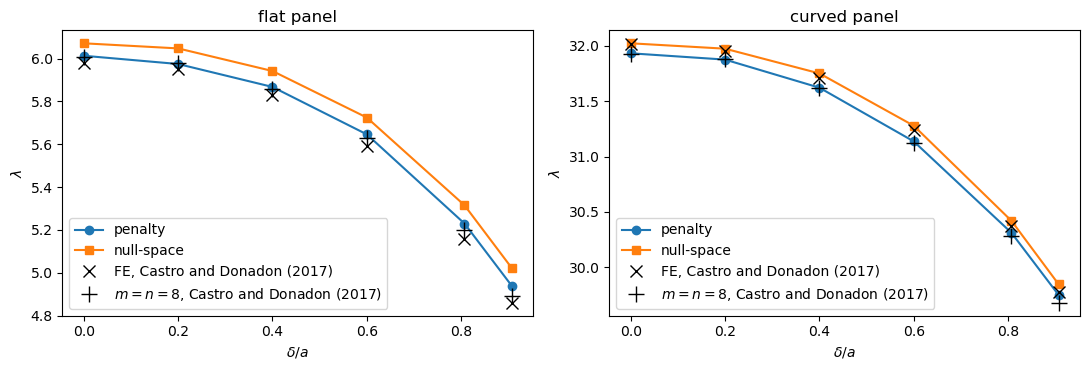

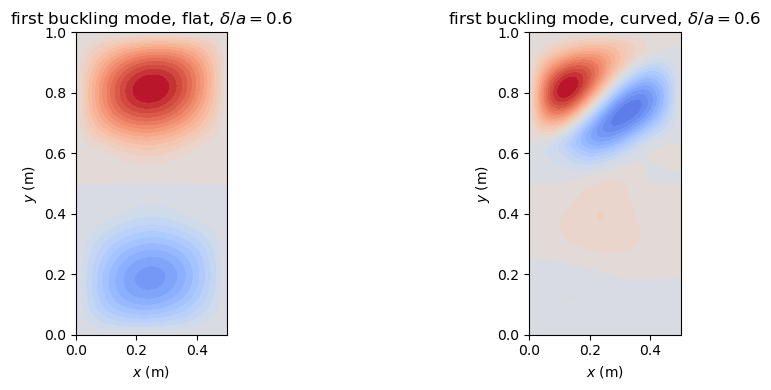

In [3]:
DEFECTS_LB = [0., 0.2, 0.4, 0.6, 0.807, 0.907]
FE_FLAT = [5.98, 5.95, 5.83, 5.59, 5.16, 4.86]  # Table 3
FE_CURVED = [32.02, 31.95, 31.71, 31.24, 30.37, 29.78]  # Table 4
SA_FLAT = [6.01, 5.98, 5.86, 5.63, 5.20, 4.89]  # Table 3, m = n = 8
SA_CURVED = [31.93, 31.88, 31.62, 31.12, 30.28, 29.68]  # Table 4, m = n = 8
lb_res = {}
lb_modes = {}
for r, geom in ((None, 'flat'), (10., 'curved')):
    for method in METHODS:
        lams = []
        for d in DEFECTS_LB:
            md, c, eigvals, eigvecs = tstiff2d_1stiff_compression(
                defect_a=d, r=r, Nxx_skin=-100., Nxx_base=-100.,
                Nxx_flange=-100., run_static_case=True, num_eigvalues=5,
                conn_method=method, **terms, **common)
            lams.append(eigvals[0])
            if d == 0.6:
                lb_modes[(geom, method)] = (md, eigvecs[:, 0])
        lb_res[(geom, method)] = np.array(lams)
        print('%-6s %-10s lambda: %s' % (geom, method, np.round(lams, 3)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, geom, fe, sa in zip(axes, ('flat', 'curved'), (FE_FLAT, FE_CURVED),
                            (SA_FLAT, SA_CURVED)):
    for method, marker in zip(METHODS, ('o-', 's-')):
        ax.plot(DEFECTS_LB, lb_res[(geom, method)], marker, label=method)
    ax.plot(DEFECTS_LB, fe, 'kx', ms=9, label='FE, Castro and Donadon (2017)')
    ax.plot(DEFECTS_LB, sa, 'k+', ms=11,
            label='$m = n = 8$, Castro and Donadon (2017)')
    ax.set_xlabel(r'$\delta/a$')
    ax.set_ylabel(r'$\lambda$')
    ax.set_title('%s panel' % geom)
    ax.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_skin(*lb_modes[('flat', 'penalty')], axes[0],
          r'first buckling mode, flat, $\delta/a = 0.6$')
plot_skin(*lb_modes[('curved', 'penalty')], axes[1],
          r'first buckling mode, curved, $\delta/a = 0.6$')
fig.tight_layout()
plt.show()

## Free vibration with different defect lengths

`tstiff2d_1stiff_freq` solves $(\boldsymbol{K}_C + \lambda^2 \boldsymbol{M})\boldsymbol{c} = \boldsymbol{0}$, with $\lambda^2 = -\omega^2$, with the boundary conditions of the vibration analysis of Castro and Donadon (2017), Fig. 8 and Section 4, p. 236: the skin is restrained by $u = v = w = 0$ at its four edges, the flange by $u = v = w = 0$ at both ends, the base has all edges free and the rotations are free everywhere. The function `tstiff2d_1stiff_freq` of compmech 0.7.1, the implementation the paper names for its results (their ref. [37]), applies the same restraints. The assembly is otherwise that of the paper: the classical laminated plate theory (their Eq. (16), p. 235, with Donnell-type kinematics; the skin and the base here use the default model of `Shell` for a cylindrical domain, `cylshell_clpt_sanders`), the mass matrix with the translational and the rotary inertia of each laminate about its mid-surface (their Eq. (B.3), p. 247), one density for every domain and $m = n = 8$ for every domain. The curved panel, $r = 10$ m, is analysed for the defect lengths of their Table 5, which gives the first natural frequency $\omega/(2\pi)$ in Hz from the FE model and from the semi-analytical model with $m = n = 8$. With the density of the authors' models, $\rho = 1300$ kg/m³, the frequencies are compared directly; the ratios $\omega(\delta)/\omega(0)$, which do not depend on $\rho$ (every frequency of a structure of one uniform density scales with $\rho^{-1/2}$), are compared as well.

penalty    first natural frequency (Hz, rho = 1300 kg/m3): [65.215 64.985 64.062 61.75  58.068 55.972]
           ratio to delta = 0: [1.     0.9965 0.9823 0.9469 0.8904 0.8583]


null-space first natural frequency (Hz, rho = 1300 kg/m3): [65.632 65.483 64.568 62.27  58.554 56.413]
           ratio to delta = 0: [1.     0.9977 0.9838 0.9488 0.8922 0.8595]
FE, Table 5, ratio to delta = 0: [1.     0.9969 0.9811 0.9444 0.8883 0.8582]


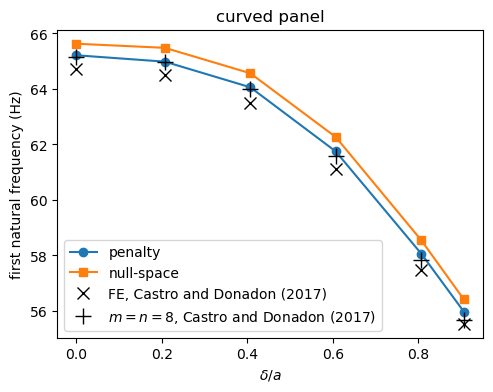

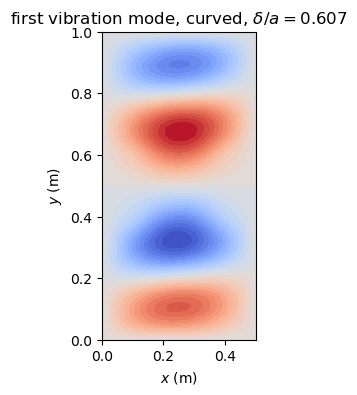

In [4]:
DEFECTS_FREQ = [0., 0.207, 0.407, 0.607, 0.807, 0.907]
FE_FREQ = np.array([64.72, 64.52, 63.50, 61.12, 57.49, 55.54])  # Table 5, Hz
SA_FREQ = np.array([65.17, 64.98, 63.99, 61.59, 57.83, 55.69])  # m = n = 8
freq_res = {}
for method in METHODS:
    freqs = []
    for d in DEFECTS_FREQ:
        md, eigvals, eigvecs = tstiff2d_1stiff_freq(
            defect_a=d, r=10., num_eigvalues=5, conn_method=method,
            **terms, **common)
        freqs.append(np.sqrt(-eigvals[0]).real/(2*np.pi))
        if d == 0.607 and method == 'null-space':
            mode_freq = (md, eigvecs[:, 0])
    freq_res[method] = np.array(freqs)
    print('%-10s first natural frequency (Hz, rho = 1300 kg/m3): %s'
          % (method, np.round(freqs, 3)))
    print('%-10s ratio to delta = 0: %s'
          % ('', np.round(freq_res[method]/freqs[0], 4)))
print('FE, Table 5, ratio to delta = 0: %s' % np.round(FE_FREQ/FE_FREQ[0], 4))
fig, ax = plt.subplots(figsize=(5.5, 4))
for method, marker in zip(METHODS, ('o-', 's-')):
    ax.plot(DEFECTS_FREQ, freq_res[method], marker, label=method)
ax.plot(DEFECTS_FREQ, FE_FREQ, 'kx', ms=9, label='FE, Castro and Donadon (2017)')
ax.plot(DEFECTS_FREQ, SA_FREQ, 'k+', ms=11,
        label='$m = n = 8$, Castro and Donadon (2017)')
ax.set_xlabel(r'$\delta/a$')
ax.set_ylabel('first natural frequency (Hz)')
ax.set_title('curved panel')
ax.legend()
plt.show()
fig, ax = plt.subplots(figsize=(5.5, 4))
plot_skin(*mode_freq, ax, r'first vibration mode, curved, $\delta/a = 0.607$')
plt.show()

## Flutter

`tstiff2d_1stiff_flutter` adds the aerodynamic stiffness of the linear piston theory for a flow along $x$ at Mach 2, speed $2 \times 343$ m/s and air density 1.2 kg/m³. It solves $(\boldsymbol{K}_C + \boldsymbol{K}_A + \lambda^2 \boldsymbol{M})\boldsymbol{c} = \boldsymbol{0}$, see [Aeroelasticity](../aeroelasticity.rst). $\boldsymbol{K}_A$ is not symmetric, and pairs of complex conjugate eigenvalues appear where two modes have coalesced. This case uses a longer panel, $a = 3$ m, with a defect of $0.1 a$ and fewer terms, the configuration of the panels unit test `tests/multidomain/test_tstiff2d_assembly.py`; no published value is available for it.

In [5]:
flutter = dict(common, a=3.)
md, eigvals, eigvecs = tstiff2d_1stiff_flutter(
    air_speed=2*343., rho_air=1.2, Mach=2, speed_sound=343.,
    run_static_case=False, conn_method='penalty', defect_a=0.1,
    m=6, n=7, mb=5, nb=6, mf=6, nf=7, num_eigvalues=10, **flutter)
print('eigenvalues lambda^2:')
for ev in eigvals:
    print('  %14.2f %+14.2fj' % (ev.real, ev.imag))
flutter_first = np.sqrt(-eigvals[0]).real

eigenvalues lambda^2:
      -233578.21     +140449.87j
      -233578.21     -140449.87j
      -238186.54     +276484.68j
      -238186.54     -276484.68j
      -238845.19     +275244.19j
      -238845.19     -275244.19j
      -335623.06          -0.00j
      -365397.99          -0.00j
      -355592.71     +273335.49j
      -355592.71     -273335.49j


## Results

The load multipliers and the frequencies are compared with the results of Castro and Donadon (2017), Tables 3 to 5: the finite element (FE) results, obtained with NX Nastran, a mesh of linear CQUAD4 elements of 0.02 m, and the stiffener's base connected to the skin with RBE2 elements, and their semi-analytical results with $m = n = 8$.

The penalty method, the method of the paper, reproduces the semi-analytical load multipliers of the paper within 1.1% for the flat panel and within 0.3% for the curved panel; it lies 0.4% to 1.6% above FE for the flat panel, growing with the defect length, and within 0.4% of FE for the curved panel. The null-space method imposes the connections exactly; its multipliers are 1.5% to 3.4% above FE for the flat panel and within 0.3% for the curved panel. The ratios $\lambda(\delta)/\lambda(0)$ agree within 1.1%. The differences to FE come from the models: the discretization of the FE mesh, the rigid RBE2 connection of the nodes of base and skin in FE against the continuity of the mid-surface displacements and rotations in the Ritz models, and the number of terms.

With the boundary conditions of Fig. 8, those of `tstiff2d_1stiff_freq`, the penalty method, the method of the paper, reproduces the semi-analytical first natural frequencies of Table 5 within 0.3% for $\delta/a \le 0.607$ and within 0.6% for the longer defects, and lies 0.7% to 1.0% above FE, where the semi-analytical values of the paper lie 0.3% to 0.8% above FE; the null-space method lies 1.4% to 1.9% above FE. The ratios $\omega(\delta)/\omega(0)$ agree with FE within 0.3% for the penalty method and within 0.5% for the null-space method, so the effect of the defect is reproduced.

The flutter row compares the real part of the square root of the first eigenvalue, one of a complex conjugate pair at this flow, with the regression value of `tests/multidomain/test_tstiff2d_assembly.py`, checked there within 0.1%, an internal check only: the published flutter analyses of stiffened panels found model the stiffener as a beam, not as plate domains.

In [6]:
for geom, fe, sa, table in (('flat', FE_FLAT, SA_FLAT, 'Table 3'),
                            ('curved', FE_CURVED, SA_CURVED, 'Table 4')):
    fe, sa = np.array(fe), np.array(sa)
    lines = ['| $\\delta/a$ | penalty | null-space | FE, %s | $m = n = 8$, %s | penalty vs FE | null-space vs FE | penalty vs $m = n = 8$ | ratio $\\lambda/\\lambda_0$, penalty | ratio, FE |' % (table, table),
             '|---|---|---|---|---|---|---|---|---|---|']
    pen, ns = lb_res[(geom, 'penalty')], lb_res[(geom, 'null-space')]
    for i, d in enumerate(DEFECTS_LB):
        lines.append('| %.3f | %.3f | %.3f | %.2f | %.2f | %+.2e | %+.2e | %+.2e | %.4f | %.4f |'
                     % (d, pen[i], ns[i], fe[i], sa[i], (pen[i] - fe[i])/fe[i],
                        (ns[i] - fe[i])/fe[i], (pen[i] - sa[i])/sa[i],
                        pen[i]/pen[0], fe[i]/fe[0]))
    display(Markdown('**Linear buckling, %s panel, load multiplier '
                     '$\\lambda$ of $N_{xx} = -100$ N/m**\n\n' % geom + '\n'.join(lines)))

lines = ['| $\\delta/a$ | penalty (Hz) | null-space (Hz) | FE, Table 5 (Hz) | $m = n = 8$, Table 5 (Hz) | penalty vs FE | null-space vs FE | penalty vs $m = n = 8$ | $m = n = 8$ vs FE |',
         '|---|---|---|---|---|---|---|---|---|']
pen, ns = freq_res['penalty'], freq_res['null-space']
for i, d in enumerate(DEFECTS_FREQ):
    lines.append('| %.3f | %.3f | %.3f | %.2f | %.2f | %+.2e | %+.2e | %+.2e | %+.2e |'
                 % (d, pen[i], ns[i], FE_FREQ[i], SA_FREQ[i],
                    (pen[i] - FE_FREQ[i])/FE_FREQ[i],
                    (ns[i] - FE_FREQ[i])/FE_FREQ[i],
                    (pen[i] - SA_FREQ[i])/SA_FREQ[i],
                    (SA_FREQ[i] - FE_FREQ[i])/FE_FREQ[i]))
display(Markdown('**Free vibration, curved panel, first natural frequency, '
                 '$\\rho = 1300$ kg/m³**\n\n' + '\n'.join(lines)))

lines = ['| $\\delta/a$ | penalty | null-space | FE, Table 5 | penalty vs FE | null-space vs FE |',
         '|---|---|---|---|---|---|']
fe = FE_FREQ/FE_FREQ[0]
pen = freq_res['penalty']/freq_res['penalty'][0]
ns = freq_res['null-space']/freq_res['null-space'][0]
for i, d in enumerate(DEFECTS_FREQ):
    lines.append('| %.3f | %.4f | %.4f | %.4f | %+.2e | %+.2e |'
                 % (d, pen[i], ns[i], fe[i], (pen[i] - fe[i])/fe[i],
                    (ns[i] - fe[i])/fe[i]))
display(Markdown('**Free vibration, curved panel, ratio '
                 '$\\omega(\\delta)/\\omega(0)$**\n\n' + '\n'.join(lines)))

results_table([('flutter, $\\sqrt{-\\lambda^2_1}$ (rad/s)', flutter_first,
                503.06, 'regression value, `test_tstiff2d_assembly.py`')])

**Linear buckling, flat panel, load multiplier $\lambda$ of $N_{xx} = -100$ N/m**

| $\delta/a$ | penalty | null-space | FE, Table 3 | $m = n = 8$, Table 3 | penalty vs FE | null-space vs FE | penalty vs $m = n = 8$ | ratio $\lambda/\lambda_0$, penalty | ratio, FE |
|---|---|---|---|---|---|---|---|---|---|
| 0.000 | 6.014 | 6.072 | 5.98 | 6.01 | +5.61e-03 | +1.53e-02 | +5.94e-04 | 1.0000 | 1.0000 |
| 0.200 | 5.975 | 6.048 | 5.95 | 5.98 | +4.21e-03 | +1.65e-02 | -8.25e-04 | 0.9936 | 0.9950 |
| 0.400 | 5.868 | 5.942 | 5.83 | 5.86 | +6.50e-03 | +1.93e-02 | +1.35e-03 | 0.9758 | 0.9749 |
| 0.600 | 5.646 | 5.725 | 5.59 | 5.63 | +1.01e-02 | +2.41e-02 | +2.92e-03 | 0.9389 | 0.9348 |
| 0.807 | 5.230 | 5.315 | 5.16 | 5.20 | +1.36e-02 | +3.01e-02 | +5.77e-03 | 0.8697 | 0.8629 |
| 0.907 | 4.940 | 5.023 | 4.86 | 4.89 | +1.64e-02 | +3.35e-02 | +1.01e-02 | 0.8214 | 0.8127 |

**Linear buckling, curved panel, load multiplier $\lambda$ of $N_{xx} = -100$ N/m**

| $\delta/a$ | penalty | null-space | FE, Table 4 | $m = n = 8$, Table 4 | penalty vs FE | null-space vs FE | penalty vs $m = n = 8$ | ratio $\lambda/\lambda_0$, penalty | ratio, FE |
|---|---|---|---|---|---|---|---|---|---|
| 0.000 | 31.933 | 32.024 | 32.02 | 31.93 | -2.71e-03 | +1.14e-04 | +1.06e-04 | 1.0000 | 1.0000 |
| 0.200 | 31.876 | 31.975 | 31.95 | 31.88 | -2.30e-03 | +7.84e-04 | -1.12e-04 | 0.9982 | 0.9978 |
| 0.400 | 31.623 | 31.752 | 31.71 | 31.62 | -2.75e-03 | +1.31e-03 | +8.53e-05 | 0.9903 | 0.9903 |
| 0.600 | 31.137 | 31.279 | 31.24 | 31.12 | -3.28e-03 | +1.25e-03 | +5.59e-04 | 0.9751 | 0.9756 |
| 0.807 | 30.312 | 30.420 | 30.37 | 30.28 | -1.91e-03 | +1.66e-03 | +1.06e-03 | 0.9492 | 0.9485 |
| 0.907 | 29.750 | 29.847 | 29.78 | 29.68 | -1.01e-03 | +2.26e-03 | +2.36e-03 | 0.9316 | 0.9300 |

**Free vibration, curved panel, first natural frequency, $\rho = 1300$ kg/m³**

| $\delta/a$ | penalty (Hz) | null-space (Hz) | FE, Table 5 (Hz) | $m = n = 8$, Table 5 (Hz) | penalty vs FE | null-space vs FE | penalty vs $m = n = 8$ | $m = n = 8$ vs FE |
|---|---|---|---|---|---|---|---|---|
| 0.000 | 65.215 | 65.632 | 64.72 | 65.17 | +7.65e-03 | +1.41e-02 | +6.94e-04 | +6.95e-03 |
| 0.207 | 64.985 | 65.483 | 64.52 | 64.98 | +7.21e-03 | +1.49e-02 | +7.61e-05 | +7.13e-03 |
| 0.407 | 64.062 | 64.568 | 63.50 | 63.99 | +8.85e-03 | +1.68e-02 | +1.13e-03 | +7.72e-03 |
| 0.607 | 61.750 | 62.270 | 61.12 | 61.59 | +1.03e-02 | +1.88e-02 | +2.60e-03 | +7.69e-03 |
| 0.807 | 58.068 | 58.554 | 57.49 | 57.83 | +1.01e-02 | +1.85e-02 | +4.12e-03 | +5.91e-03 |
| 0.907 | 55.972 | 56.413 | 55.54 | 55.69 | +7.78e-03 | +1.57e-02 | +5.07e-03 | +2.70e-03 |

**Free vibration, curved panel, ratio $\omega(\delta)/\omega(0)$**

| $\delta/a$ | penalty | null-space | FE, Table 5 | penalty vs FE | null-space vs FE |
|---|---|---|---|---|---|
| 0.000 | 1.0000 | 1.0000 | 1.0000 | +0.00e+00 | +0.00e+00 |
| 0.207 | 0.9965 | 0.9977 | 0.9969 | -4.43e-04 | +8.35e-04 |
| 0.407 | 0.9823 | 0.9838 | 0.9811 | +1.19e-03 | +2.70e-03 |
| 0.607 | 0.9469 | 0.9488 | 0.9444 | +2.63e-03 | +4.66e-03 |
| 0.807 | 0.8904 | 0.8922 | 0.8883 | +2.39e-03 | +4.36e-03 |
| 0.907 | 0.8583 | 0.8595 | 0.8582 | +1.31e-04 | +1.61e-03 |

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| flutter, $\sqrt{-\lambda^2_1}$ (rad/s) | 503.056 | 503.06 | -7.76e-06 | regression value, `test_tstiff2d_assembly.py` |

## References

1. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.